# Lab: Building a Reproducible Analysis Workflow

Choose your own documented dataset, develop three distinct research questions, and answer each using the six-step workflow from the Pokémon lecture. You may reuse your visual thinking dataset, but develop new questions rather than repeat its single-feature charts.


## Learning goals

- Develop three questions that can be answered with your chosen data.
- Inspect and document a dataset using its data dictionary.
- Select, group, summarize, or calculate features with Pandas.
- Connect displayed evidence, contextual sanity checks, conclusions, and limitations.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context? Do a few original records support the meaning of the calculation?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?


## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the work and checking suggestions. Disclose whether you used AI in the final reflection.


## Find and document your dataset

Choose your own documented CSV dataset from [Kaggle](https://www.kaggle.com/datasets) or another reputable source. You may reuse the dataset from the visual thinking lab. Choose data with:

- a clearly identified publisher or creator;
- a data dictionary or documentation explaining observations and features;
- at least one categorical and one quantitative feature;
- enough information to answer three distinct questions involving calculations or comparisons;
- content appropriate to share in class, without private or personally identifying information; and
- a manageable file size.

Save the CSV in this notebook's `data` folder. Use a descriptive DataFrame name ending in `_df` throughout your analysis.


**What is the dataset's title, publisher or creator, direct source URL, and data dictionary URL or location?**

Your answer: https://www.kaggle.com/datasets/sdcloud/historical-bakery-sales-dataset  

This dataset is a synthetic dataset meant for students studying data science


**Briefly describe the dataset and relevant features using its documentation. What does one row represent? Include units and the meaning of blank values where documented.**

Your answer: Overview
This dataset is a synthetic bakery retail dataset designed for educational, academic, and machine learning research purposes. It contains 19,321 records and 40 columns representing bakery transactions, customer characteristics, product details, pricing, promotions, environmental conditions, inventory, and business performance.

The dataset covers a two-year period from January 1, 2023, to December 31, 2024, and includes 35 unique bakery products across three stores. It provides a structured foundation for studying bakery sales patterns and developing data-driven decision-support approaches.

Dataset Contents
The dataset includes the following categories of information:

Customer information: Customer age, gender, customer segment, loyalty membership, and customer ratings.
Date and time: Transaction dates, year, month, day, day of the week, weekend indicator, hour, and time.
Product information: Product name, category, shelf life, storage type, and perishability level.
Pricing and sales: Quantity, unit price, cost price, selling price, discount percentage, and total bill.
Promotions and external factors: Promotion status, promotion type, festival, season, weather, and temperature.
Inventory and waste: Units produced, units sold, unsold units, available stock, and waste percentage.
Business performance: Profit, payment method, and store identification.



## Plan three investigations

Develop three distinct research questions about your dataset. Each must require a calculation or comparison, not simply looking up a value. Consider grouped averages, percentages meeting a condition, or comparisons between features, as in the lecture; adapt the questions to what your data means. Complete all six steps for each question. Record each prediction before running its calculations.


## Investigation 1

### Step 1: Question

State a specific question that your dataset can answer. Define any important groups or comparisons.


**What is your research question 1?**

Your answer: What's the average transaction total? 


### Prediction — before calculating


**What do you predict the result will be, and why?**

Your answer: I would imagine the average transaction to be somewhere between 20-30 dollars. I work in a bakery and that seems like it would be close to the average transaction total. 


### Step 2: Data


Import Pandas and load your CSV into a descriptively named DataFrame ending in `_df`. Inspect the data once here, using separate cells for each operation.


In [1]:
# Import pandas as pd.
import pandas as pd

In [3]:
# Read your CSV using a relative path and a descriptive DataFrame name ending in _df.
bakery_df = pd.read_csv('data/bakery_sales_dataset.csv')

In [4]:
# Display the first five rows with .head().
bakery_df.head()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
0,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST02,8,6,2,2,25.0,141.48,4
1,ORD00001,CUST0328,46,Other,Young Professional,Yes,2023-01-01,2023,1,1,...,Dry Storage,Low,ST02,4,3,1,1,25.0,39.96,4
2,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Refrigerated,Very High,ST03,3,2,1,1,33.3,103.83,4
3,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Dry Storage,Low,ST03,13,10,3,2,23.1,79.73,4
4,ORD00002,CUST0016,21,Female,Student,No,2023-01-01,2023,1,1,...,Room Temperature,Very High,ST03,4,3,1,1,25.0,10.08,4


In [5]:
# Display the last five rows with .tail().
bakery_df.tail()

,Order_ID,Customer_ID,Customer_Age,Customer_Gender,Customer_Segment,Loyalty_Member,Date,Year,Month,Day,...,Storage_Type,Perishability,Store_ID,Units_Produced,Units_Sold,Unsold_Units,Stock_Available,Waste_Pct,Profit,Customer_Rating
19316,ORD06574,CUST0206,16,Female,Student,Yes,2024-12-31,2024,12,31,...,Refrigerated,Very High,ST01,2,1,1,1,50.0,18.85,4
19317,ORD06575,CUST0017,16,Male,Student,Yes,2024-12-31,2024,12,31,...,Refrigerated,Very High,ST02,2,1,1,1,50.0,166.09,4
19318,ORD06575,CUST0017,16,Male,Student,Yes,2024-12-31,2024,12,31,...,Room Temperature,High,ST02,2,1,1,1,50.0,69.18,4
19319,ORD06576,CUST0219,31,Female,Young Professional,No,2024-12-31,2024,12,31,...,Room Temperature,Very High,ST01,6,5,1,1,16.7,64.85,3
19320,ORD06576,CUST0219,31,Female,Young Professional,No,2024-12-31,2024,12,31,...,Refrigerated,Very High,ST01,2,1,1,1,50.0,19.75,3


In [6]:
# Display .shape.
bakery_df.shape

(19321, 40)

In [7]:
# Run .info().
bakery_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19321 entries, 0 to 19320
Data columns (total 40 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Order_ID             19321 non-null  object 
 1   Customer_ID          19321 non-null  object 
 2   Customer_Age         19321 non-null  int64  
 3   Customer_Gender      19321 non-null  object 
 4   Customer_Segment     19321 non-null  object 
 5   Loyalty_Member       19321 non-null  object 
 6   Date                 19321 non-null  object 
 7   Year                 19321 non-null  int64  
 8   Month                19321 non-null  int64  
 9   Day                  19321 non-null  int64  
 10  Day_of_Week          19321 non-null  object 
 11  Weekend              19321 non-null  object 
 12  Hour                 19321 non-null  int64  
 13  Time                 19321 non-null  object 
 14  Season               19321 non-null  object 
 15  Festival             3315 non-null  

In [8]:
# Display missing-value counts for each feature.
bakery_df.isnull().sum()

Order_ID                   0
Customer_ID                0
Customer_Age               0
Customer_Gender            0
Customer_Segment           0
Loyalty_Member             0
Date                       0
Year                       0
Month                      0
Day                        0
Day_of_Week                0
Weekend                    0
Hour                       0
Time                       0
Season                     0
Festival               16006
Weather                    0
Temperature                0
Product                    0
Category                   0
Quantity                   0
Unit_Price                 0
Cost_Price                 0
Discount_Percentage        0
Selling_Price              0
Total_Bill                 0
Payment_Method             0
Promotion_Applied          0
Promotion_Type         13826
Shelf_Life_Days            0
Storage_Type               0
Perishability              0
Store_ID                   0
Units_Produced             0
Units_Sold    

**Which observations and features will you use? Explain relevant units, any filtering, and how you will handle missing or not-applicable values using the dictionary. For a percentage, define the denominator.**

Your answer: There are missing information in promotion type and festival. I will not be using those I will be using profit to calculate the transaction totals. 


### Step 3: Evidence

Write the code that answers your question. Break the analysis into separate cells for individual operations, as in the lecture, and add cells as needed. Display intermediate results where useful and the final result that answers the question. Explain any new calculated features. You may display a grouped summary directly without assigning it to a variable.


In [9]:
# Prepare, filter, or calculate features as needed; display useful intermediate results.
bakery_df['Profit'].value_counts()

Profit
18.80     16
35.28     15
18.14     14
20.94     14
17.40     14
          ..
145.60     1
105.16     1
59.85      1
491.84     1
173.27     1
Name: count, Length: 8460, dtype: int64

In [12]:
# Calculate and display the evidence that answers your question. Add cells as needed.
bakery_df['Profit'].mean().round(2)

np.float64(59.2)

**Which specific value or comparison answers your question? Explain how your calculations connect the selected data to that result.**

Your answer: I used the mean to find the average transaction amount.


### Step 4: Check

Perform a sanity check tied to the meaning of your question. Explain what values or patterns would make you suspicious and whether your result makes sense. Depending on the analysis, consider plausible values and units, whether indicators match original labels, or whether the ranges within comparison groups match their definitions. Use additional code only when it helps this check; do not simply repeat the initial row count or missing-value inspection. An unexpected result is a reason to investigate, not to change the result to fit your prediction.


In [ ]:
# Optional: add a targeted sanity check if code would help.


**What would make you suspicious, and why? Does your evidence make sense in context? Describe any issue you found and how you addressed it.**

Your answer: Having a negative amount would be alarming for transaction total


### Step 5: Conclusion


**Answer your research question in a sentence using the numerical evidence. How does it compare with your prediction?**

Your answer: My prediction for this was around 20-30 dollars. Calculating the mean across all transaction the average came out to 59.20 dollars.


### Step 6: Limitation


**What should a reader avoid concluding from this result, and why? Connect your limitation to this question and dataset.**

Your answer: The reader should avoid concluding that a bakery's average cost per item is around 59 dollars. Although the average sale is around 59 dollars, the customers who are spending that much are purchasing many items. 


## Investigation 2

### Step 1: Question

State a specific question that your dataset can answer. Define any important groups or comparisons.


**What is your research question 2?**

Your answer: What's the average customer age?


### Prediction — before calculating


**What do you predict the result will be, and why?**

Your answer: My guess is around 40 years old.


### Step 2: Data


Reuse the DataFrame and initial inspection from Investigation 1. Identify the observations and features relevant to this question; inspect additional features only if needed.


**Which observations and features will you use? Explain relevant units, any filtering, and how you will handle missing or not-applicable values using the dictionary. For a percentage, define the denominator.**

Your answer: I will be using customer_age to calculate the average customer age. 


### Step 3: Evidence

Write the code that answers your question. Break the analysis into separate cells for individual operations, as in the lecture, and add cells as needed. Display intermediate results where useful and the final result that answers the question. Explain any new calculated features. You may display a grouped summary directly without assigning it to a variable.


In [13]:
# Prepare, filter, or calculate features as needed; display useful intermediate results.
bakery_df['Customer_Age'].value_counts()

Customer_Age
16    2126
35     772
32     654
25     610
42     603
34     594
26     592
28     588
18     581
40     551
48     536
30     528
43     495
33     478
37     475
27     469
31     434
36     420
38     403
50     401
52     356
19     344
23     339
45     339
49     334
47     326
41     314
24     288
44     282
54     270
29     264
46     262
56     254
51     243
20     242
22     200
58     196
21     190
39     184
17     180
66     165
53     161
59     159
57     147
60     136
62     122
64     120
63     119
55     111
71      75
67      70
61      57
73      49
72      33
70      32
69      24
65      24
Name: count, dtype: int64

In [15]:
# Calculate and display the evidence that answers your question. Add cells as needed.
bakery_df['Customer_Age'].mean().round()

np.float64(36.0)

**Which specific value or comparison answers your question? Explain how your calculations connect the selected data to that result.**

Your answer: I used the mean of the Customer's ages to calculate the average customer age.


### Step 4: Check

Perform a sanity check tied to the meaning of your question. Explain what values or patterns would make you suspicious and whether your result makes sense. Depending on the analysis, consider plausible values and units, whether indicators match original labels, or whether the ranges within comparison groups match their definitions. Use additional code only when it helps this check; do not simply repeat the initial row count or missing-value inspection. An unexpected result is a reason to investigate, not to change the result to fit your prediction.


In [ ]:
# Optional: add a targeted sanity check if code would help.


**What would make you suspicious, and why? Does your evidence make sense in context? Describe any issue you found and how you addressed it.**

Your answer: Having a negative value would be indicitive of miscalculation 


### Step 5: Conclusion


**Answer your research question in a sentence using the numerical evidence. How does it compare with your prediction?**

Your answer: My prediction was around 40 years old for the average customer and the mean shows the average customer is 36. I was not too far off. 


### Step 6: Limitation


**What should a reader avoid concluding from this result, and why? Connect your limitation to this question and dataset.**

Your answer: The reader should avoid concluding that a bakery's target customer are individuals in their 30's. 


## Investigation 3

### Step 1: Question

State a specific question that your dataset can answer. Define any important groups or comparisons.


**What is your research question 3?**

Your answer: How does Weather effect sales?


### Prediction — before calculating


**What do you predict the result will be, and why?**

Your answer: I live in the mountains and we have a full range of weather conditions, from sunny summers to snowy winters. I live in a resort town and winter is our busiest season. I'm curious how Weather effects sales. 


### Step 2: Data


Reuse the DataFrame and initial inspection from Investigation 1. Identify the observations and features relevant to this question; inspect additional features only if needed.


**Which observations and features will you use? Explain relevant units, any filtering, and how you will handle missing or not-applicable values using the dictionary. For a percentage, define the denominator.**

Your answer: I will have to compare weather to sales


### Step 3: Evidence

Write the code that answers your question. Break the analysis into separate cells for individual operations, as in the lecture, and add cells as needed. Display intermediate results where useful and the final result that answers the question. Explain any new calculated features. You may display a grouped summary directly without assigning it to a variable.


In [18]:
# Prepare, filter, or calculate features as needed; display useful intermediate results.
bakery_df.groupby('Weather')['Profit'].mean().round(2)


Weather
Clear    60.74
Cold     59.31
Foggy    63.68
Hot      58.19
Humid    57.37
Rainy    57.39
Name: Profit, dtype: float64

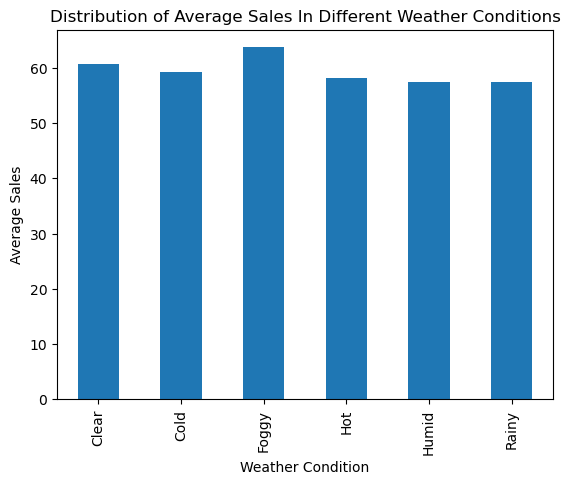

In [20]:
# Calculate and display the evidence that answers your question. Add cells as needed.
import matplotlib.pyplot as plt
bakery_df.groupby('Weather')['Profit'].mean().round(2).plot(kind='bar')
plt.title('Distribution of Average Sales In Different Weather Conditions')
plt.ylabel('Average Sales')
plt.xlabel('Weather Condition')
plt.show()


**Which specific value or comparison answers your question? Explain how your calculations connect the selected data to that result.**

Your answer: I Grouped Weather to the mean of average sales to show the average transaction amount connected to different weather patterns. 


### Step 4: Check

Perform a sanity check tied to the meaning of your question. Explain what values or patterns would make you suspicious and whether your result makes sense. Depending on the analysis, consider plausible values and units, whether indicators match original labels, or whether the ranges within comparison groups match their definitions. Use additional code only when it helps this check; do not simply repeat the initial row count or missing-value inspection. An unexpected result is a reason to investigate, not to change the result to fit your prediction.


In [ ]:
# Optional: add a targeted sanity check if code would help.


**What would make you suspicious, and why? Does your evidence make sense in context? Describe any issue you found and how you addressed it.**

Your answer: Having an average amount that was hugely disconnected from the previously calculated average transaction amount



### Step 5: Conclusion


**Answer your research question in a sentence using the numerical evidence. How does it compare with your prediction?**

Your answer: The average customer spends more money during foggy weather than any other weather condition with an average of 63.68 dollars per sale. 


### Step 6: Limitation


**What should a reader avoid concluding from this result, and why? Connect your limitation to this question and dataset.**

Your answer: The reader should avoid assuming that prices go up in a bakery when the weather is foggy. The reader should avoid assuming that a bakery will be busiest when the weather is foggy. 


## AI-use reflection


**State whether you used an AI tool. If you did, describe one suggestion you checked and what you accepted, changed, or rejected. If you did not, state that you did not use one.**

Your answer:


## Submission checklist

- Include your chosen dataset, source, and dictionary reference.
- Complete three distinct questions, each with a prediction and all six workflow steps.
- Use a descriptive DataFrame name ending in `_df` and relative file paths.
- Restart the kernel and run all cells in order; verify that numerical claims match displayed output.
- Include a contextual sanity check, supported conclusion, and relevant limitation for each question.
- Complete every written response and the AI-use reflection.
